# 4. Comparison between cafeterias

Do the three cafeterias follow the same rhythm? Correlations are computed only over
intervals where both cafeterias have valid data, at three time scales (15 min, 1 h, 1 day).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

import eda_utils as u

u.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

df = u.build_dataset()
wide = df.pivot_table(index=df.index, columns="cafeteria", values="consumption_L")[u.CAFETERIAS]

## 4.1 Correlation at different time scales

In [2]:
def pairwise(frame):
    rows = {}
    for a, b in [("CAF_C1", "CAF_CENTRAL"), ("CAF_C1", "CAF_C3"), ("CAF_CENTRAL", "CAF_C3")]:
        pair = frame[[a, b]].dropna()
        rows[f"{a} – {b}"] = {"r": pair[a].corr(pair[b]), "n": len(pair)}
    return pd.DataFrame(rows).T

hourly = wide.resample("1h").sum(min_count=4)
hourly[wide.resample("1h").count() < 4] = np.nan
daily = wide.resample("1D").sum(min_count=96)

pd.concat({"15 min": pairwise(wide), "1 h": pairwise(hourly), "1 day": pairwise(daily)}, axis=1)

15 min              1 h            1 day        
                          r          n     r          n     r       n
CAF_C1 – CAF_CENTRAL  0.430  4,965.000 0.492  1,011.000 0.712   7.000
CAF_C1 – CAF_C3       0.430  4,836.000 0.501    982.000 0.609   7.000
CAF_CENTRAL – CAF_C3  0.349 49,734.000 0.430 12,151.000 0.628 353.000

## 4.2 Lagged correlation (hourly)

Correlation between `CAF_CENTRAL` and `CAF_C3` when one series is shifted by −3 h to +3 h.
A maximum away from 0 would mean that one cafeteria systematically starts earlier.

,r
-3,0.327
-2,0.344
-1,0.382
0,0.430
1,0.420
2,0.286
3,0.195


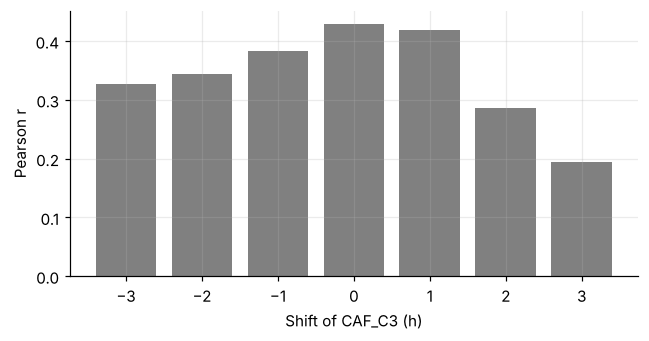

In [3]:
lags = range(-3, 4)
lagged = pd.Series({lag: hourly["CAF_CENTRAL"].corr(hourly["CAF_C3"].shift(lag)) for lag in lags})
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(lagged.index, lagged.values, color="0.5")
ax.set_xlabel("Shift of CAF_C3 (h)")
ax.set_ylabel("Pearson r")
fig.tight_layout()
u.savefig(fig, "04_lagged_correlation")
lagged.to_frame("r")

## 4.3 Normalised hourly profiles

Each profile is divided by its own daily mean, so that the shapes can be compared regardless
of the size of the cafeteria (weekdays during classes, holidays excluded).

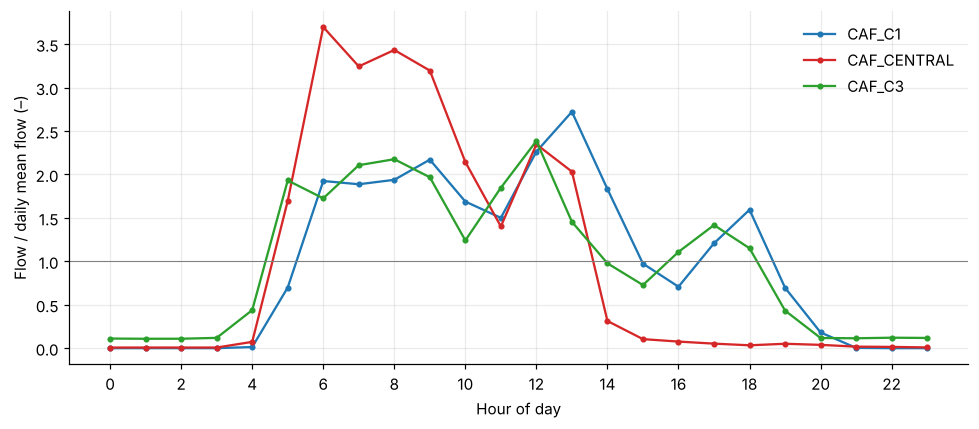

In [4]:
reg = df.dropna(subset=["consumption_L"])
reg = reg[reg["is_weekday"] & ~reg["is_holiday"] & (reg["academic_period"] == "classes")]
fig, ax = plt.subplots(figsize=(9, 4))
for caf in u.CAFETERIAS:
    d = reg[reg["cafeteria"] == caf]
    p = d.groupby(d.index.hour)["flow_Ls"].mean()
    ax.plot(p.index, p / p.mean(), "o-", ms=3, color=u.COLORS[caf], label=caf)
ax.axhline(1, color="0.5", lw=0.7)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Flow / daily mean flow (–)")
ax.legend()
fig.tight_layout()
u.savefig(fig, "04_normalised_profiles")

## Observations

* At 15-min resolution the cafeterias are only moderately correlated (r = 0.35–0.43), because
  each one has its own meal times. The correlation increases with aggregation: at daily scale,
  `CAF_CENTRAL` and `CAF_C3` reach r = 0.63 over 353 common days, driven by the shared weekly
  and academic calendar. Pairs with `CAF_C1` have only 7 common complete days.
* The lagged correlation peaks at 0 h: the cafeterias start and stop their activity together.
* The normalised profiles show the difference in service type: `CAF_CENTRAL` concentrates its
  use in the morning (3.7 times its daily mean at 06:00), while `CAF_C1` and `CAF_C3` spread
  it over three meals.